# Vanishing & Exploding Gradients in Deep Neural Networks

In this notebook we will **see** the problem, **measure** it, and **fix** it, using plain PyTorch.

**Learning objectives**

1. Explain, using the chain rule, why gradients shrink or grow *exponentially* with depth.
2. Measure per-layer gradient norms in PyTorch and use them as a diagnostic.
3. Reproduce a **vanishing** gradient (deep sigmoid network) and an **exploding** gradient (badly scaled initialisation).
4. Compare the standard remedies: activation choice, weight initialisation, normalisation, residual connections and gradient clipping.

**Roadmap**

| # | Section | What we do |
|---|---------|------------|
| 1 | Setup | Imports, seed, device |
| 2 | Intuition | Chain rule, a scalar toy model, activation derivatives |
| 3 | Data | A small 2-D classification problem (two moons) |
| 4 | Model | A configurable deep MLP, init schemes, gradient probes |
| 5 | Training loop | Standard PyTorch loop that also records per-layer gradient norms |
| 6 | Experiment 1 | Vanishing gradients |
| 7 | Experiment 2 | Exploding gradients |
| 8 | Fixes | Side-by-side comparison of remedies |
| 9 | Takeaways & exercises | |

> We deliberately use plain **SGD** for most experiments. Adaptive optimisers such as Adam rescale each parameter's update and partly hide the problem (see the exercises).

## 1. Setup

In [1]:
import math, random, time, copy
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device)

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "grid.alpha": 0.3})

torch 2.15.0+cu132 | device: cpu


## 2. Why do gradients vanish or explode?

Consider a network with $L$ layers, $h_l = \phi(W_l h_{l-1})$, and a loss $\mathcal{L}$ computed from $h_L$.
Backpropagation gives the gradient reaching the **first** layer as a long product:

$$
\frac{\partial \mathcal{L}}{\partial h_0}
= \frac{\partial \mathcal{L}}{\partial h_L}\;\prod_{l=1}^{L} \operatorname{diag}\big(\phi'(z_l)\big)\, W_l ,
\qquad z_l = W_l h_{l-1}.
$$

Every layer contributes one factor. If a typical factor has magnitude **below 1**, the product shrinks like $r^L$ (**vanishing**).
If it is **above 1**, the product grows like $r^L$ (**exploding**). Depth turns a small per-layer effect into an exponential one.

Two things set the size of each factor:

* the **weights** $W_l$ (their scale, i.e. the initialisation and what training does to it), and
* the **activation derivative** $\phi'$ (for sigmoid it is at most $0.25$).

### 2.1 A scalar toy model
Replace each layer's Jacobian by a single number $r$ and look at $r^{L}$:

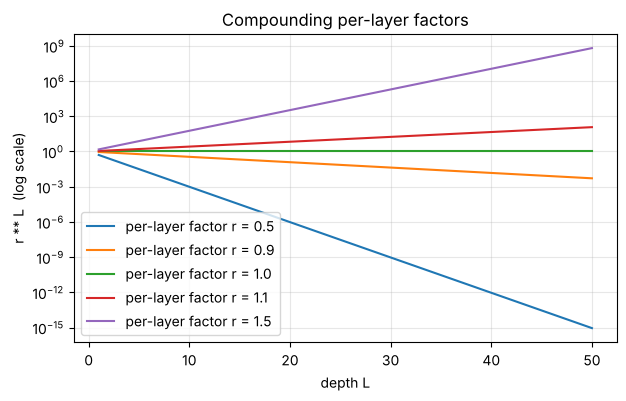

r = 0.5  -> r**50 = 8.882e-16
r = 0.9  -> r**50 = 5.154e-03
r = 1.0  -> r**50 = 1.000e+00
r = 1.1  -> r**50 = 1.174e+02
r = 1.5  -> r**50 = 6.376e+08


In [2]:
depths = np.arange(1, 51)
factors = [0.5, 0.9, 1.0, 1.1, 1.5]

fig, ax = plt.subplots()
for r in factors:
    ax.plot(depths, r ** depths.astype(float), label=f"per-layer factor r = {r}")
ax.set_yscale("log")
ax.set_xlabel("depth L")
ax.set_ylabel("r ** L  (log scale)")
ax.set_title("Compounding per-layer factors")
ax.legend()
plt.show()

for r in factors:
    print(f"r = {r:<4} -> r**50 = {r**50:.3e}")

Even a factor of $0.9$ (only 10% shrinkage per layer) leaves ~0.5% of the signal after 50 layers, and $1.1$ amplifies it ~117×.
Only a factor *very close to 1* is stable, which is exactly what good initialisation and architecture design try to achieve.

### 2.2 The activation function contributes a factor too
Below are the derivatives of three common activations. Sigmoid's derivative never exceeds $0.25$,
so even with perfectly scaled weights, a deep sigmoid network multiplies the gradient by something $\le 0.25$ at every layer.

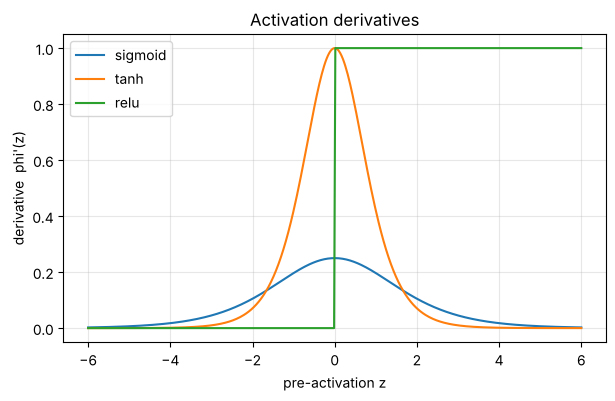

max sigmoid'(z)      = 0.25
0.25 ** 20           = 9.09e-13   (best-case gradient scale after 20 sigmoid layers)


In [3]:
z = torch.linspace(-6, 6, 400, requires_grad=True)

fig, ax = plt.subplots()
for name, fn in [("sigmoid", torch.sigmoid), ("tanh", torch.tanh), ("relu", torch.relu)]:
    z.grad = None
    fn(z).sum().backward()
    ax.plot(z.detach().numpy(), z.grad.numpy(), label=name)
ax.set_xlabel("pre-activation z")
ax.set_ylabel("derivative  phi'(z)")
ax.set_title("Activation derivatives")
ax.legend()
plt.show()

print("max sigmoid'(z)      =", 0.25)
print("0.25 ** 20           = %.2e   (best-case gradient scale after 20 sigmoid layers)" % 0.25 ** 20)

## 3. Data

A small 2-D "two moons" classification problem keeps everything fast and lets us focus on gradients rather than data.
A *shallow* network solves it easily, so any failure of a *deep* network is down to optimisation, not capacity.

train: (2250, 2) | val: (750, 2) | batches/epoch: 36


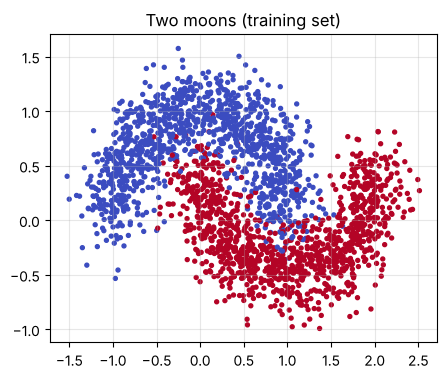

In [4]:
X, y = make_moons(n_samples=3000, noise=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

X_train, X_val = torch.tensor(X_train, dtype=torch.float32), torch.tensor(X_val, dtype=torch.float32)
y_train, y_val = torch.tensor(y_train, dtype=torch.float32), torch.tensor(y_val, dtype=torch.float32)

train_ds = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)

print("train:", tuple(X_train.shape), "| val:", tuple(X_val.shape), "| batches/epoch:", len(train_loader))

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", s=8)
ax.set_title("Two moons (training set)")
plt.show()

## 4. A configurable deep MLP

One class lets us switch the ingredients we want to study:

* `depth` : number of hidden `Linear` layers (all of width `width`),
* `act` : `"sigmoid"`, `"tanh"` or `"relu"`,
* `norm` : `None` or `"bn"` (BatchNorm after every linear layer),
* `residual` : add skip connections `h = h + f(h)` between hidden layers.

In [5]:
class DeepMLP(nn.Module):
    def __init__(self, depth=20, width=64, act="relu", norm=None, residual=False, in_dim=2, out_dim=1):
        super().__init__()
        acts = {"sigmoid": nn.Sigmoid, "tanh": nn.Tanh, "relu": nn.ReLU}
        self.residual = residual
        dims = [in_dim] + [width] * depth
        self.linears = nn.ModuleList([nn.Linear(dims[i], dims[i + 1]) for i in range(depth)])
        self.norms = nn.ModuleList([nn.BatchNorm1d(width) if norm == "bn" else nn.Identity() for _ in range(depth)])
        self.act = acts[act]()
        self.head = nn.Linear(width, out_dim)

    def forward(self, x):
        h = x
        for i, (lin, nrm) in enumerate(zip(self.linears, self.norms)):
            out = self.act(nrm(lin(h)))
            h = h + out if (self.residual and i > 0) else out   # skip connection (needs equal widths)
            # note: the first layer maps in_dim -> width, so it cannot have a skip
        return self.head(h).squeeze(-1)

m = DeepMLP(depth=20, width=64, act="sigmoid")
print(m)
print("parameters:", sum(p.numel() for p in m.parameters()))

DeepMLP(
  (linears): ModuleList(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1-19): 19 x Linear(in_features=64, out_features=64, bias=True)
  )
  (norms): ModuleList(
    (0-19): 20 x Identity()
  )
  (act): Sigmoid()
  (head): Linear(in_features=64, out_features=1, bias=True)
)
parameters: 79297


### 4.1 Weight initialisation schemes
PyTorch's default `nn.Linear` init is a fairly small uniform distribution. We add three explicit schemes plus a `scale` knob
that multiplies the weights after initialisation, which is handy for *deliberately* breaking things.

| scheme | std of weights | designed for |
|--------|----------------|--------------|
| `default` | PyTorch default | (generic) |
| `xavier` | $\sqrt{2/(n_{in}+n_{out})}$ | sigmoid / tanh |
| `he` | $\sqrt{2/n_{in}}$ | ReLU |

In [6]:
def init_weights(model, scheme="default", scale=1.0):
    for mod in model.modules():
        if isinstance(mod, nn.Linear):
            if scheme == "xavier":
                nn.init.xavier_normal_(mod.weight)
                nn.init.zeros_(mod.bias)
            elif scheme == "he":
                nn.init.kaiming_normal_(mod.weight, nonlinearity="relu")
                nn.init.zeros_(mod.bias)
            elif scheme != "default":
                raise ValueError(scheme)
            if scheme != "default":
                mod.weight.data.mul_(scale)
    return model

# ---- gradient probes ---------------------------------------------------------
criterion = nn.BCEWithLogitsLoss()

def linear_layers(model):
    # all Linear layers in forward order (hidden layers first, output head last)
    return [m for m in model.modules() if isinstance(m, nn.Linear)]

def layer_grad_norms(model):
    return [l.weight.grad.norm().item() for l in linear_layers(model)]

def grads_at_init(model, n=512):
    # per-layer gradient norms for one batch, computed on a copy so `model` is untouched
    probe = copy.deepcopy(model).to(device).train()
    xb, yb = X_train[:n].to(device), y_train[:n].to(device)
    probe.zero_grad()
    criterion(probe(xb), yb).backward()
    return np.array(layer_grad_norms(probe))

g = grads_at_init(init_weights(DeepMLP(depth=5, act="relu"), "he"))
print("per-layer grad norms (5-layer ReLU/He):", np.round(g, 4))

per-layer grad norms (5-layer ReLU/He): [0.2302 1.0956 0.9329 0.9783 1.0807 1.0886]


## 5. The training loop

This is the standard PyTorch loop (`zero_grad` → forward → loss → `backward` → `step`) with two additions:

1. right after `backward()` we **record the per-layer gradient norms** (before any clipping),
2. we stop early and flag the run if the loss becomes `NaN`/`inf` (divergence).

In [7]:
@torch.no_grad()
def evaluate(model, X, y):
    model.eval()
    logits = model(X.to(device))
    loss = criterion(logits, y.to(device)).item()
    acc = ((logits > 0).float() == y.to(device)).float().mean().item()
    return loss, acc

def train(model, epochs=40, lr=0.05, clip=None, verbose=False):
    model.to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "val_acc": [], "grad_norms": [], "step_loss": [], "diverged": False}

    for epoch in range(epochs):
        model.train()
        running, seen = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            hist["grad_norms"].append(layer_grad_norms(model))      # record BEFORE clipping
            hist["step_loss"].append(loss.item())
            if clip is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
            if not math.isfinite(loss.item()):
                hist["diverged"] = True
                break
            running += loss.item() * xb.size(0)
            seen += xb.size(0)
        if hist["diverged"]:
            if verbose: print(f"epoch {epoch+1:3d} | loss became non-finite -> diverged")
            break
        vl, va = evaluate(model, X_val, y_val)
        hist["train_loss"].append(running / seen)
        hist["val_loss"].append(vl)
        hist["val_acc"].append(va)
        if verbose and (epoch % 10 == 0 or epoch == epochs - 1):
            print(f"epoch {epoch+1:3d} | train loss {running/seen:.4f} | val loss {vl:.4f} | val acc {va:.3f}")
    hist["grad_norms"] = np.array(hist["grad_norms"])
    return hist

def plot_layer_grads(curves, title, ylabel="gradient norm of W  (log scale)"):
    fig, ax = plt.subplots()
    for label, vals in curves.items():
        ax.plot(range(1, len(vals) + 1), vals, marker="o", ms=3, label=label)
    ax.set_yscale("log")
    ax.set_xlabel("layer index (1 = closest to input, last = output head)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    plt.show()

## 6. Experiment 1 — Vanishing gradients

### 6.1 How does depth affect the gradient reaching the first layer?
For several depths we build a **sigmoid** network (PyTorch default init) and a **ReLU + He-init** network, and compare the
gradient norm at the **first** layer with the norm at the **last hidden** layer.
(We stop at depth 25: a little deeper, the sigmoid network's first-layer gradient underflows to exactly 0 in float32.)

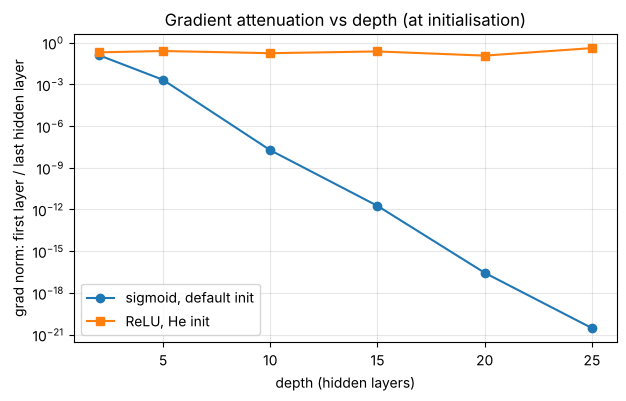

depth  2 | sigmoid: 1.27e-01 | relu+He: 2.01e-01
depth  5 | sigmoid: 2.12e-03 | relu+He: 2.51e-01
depth 10 | sigmoid: 1.84e-08 | relu+He: 1.75e-01
depth 15 | sigmoid: 1.82e-12 | relu+He: 2.34e-01
depth 20 | sigmoid: 2.78e-17 | relu+He: 1.17e-01
depth 25 | sigmoid: 2.93e-21 | relu+He: 4.06e-01


In [8]:
def depth_sweep(act, init, depths):
    ratios = []
    for d in depths:
        set_seed(0)
        model = init_weights(DeepMLP(depth=d, act=act), init)
        g = grads_at_init(model)
        ratios.append(g[0] / g[-2])        # first layer / last hidden layer
    return np.array(ratios)

depths = [2, 5, 10, 15, 20, 25]
r_sig = depth_sweep("sigmoid", "default", depths)
r_rel = depth_sweep("relu", "he", depths)

fig, ax = plt.subplots()
ax.plot(depths, r_sig, "o-", label="sigmoid, default init")
ax.plot(depths, r_rel, "s-", label="ReLU, He init")
ax.set_yscale("log")
ax.set_xlabel("depth (hidden layers)")
ax.set_ylabel("grad norm: first layer / last hidden layer")
ax.set_title("Gradient attenuation vs depth (at initialisation)")
ax.legend()
plt.show()

for d, a, b in zip(depths, r_sig, r_rel):
    print(f"depth {d:2d} | sigmoid: {a:.2e} | relu+He: {b:.2e}")

On a log axis the sigmoid curve is close to a straight line going down: beyond a few layers, each extra five layers costs roughly four to five orders of magnitude of gradient.
The ReLU + He network stays roughly constant (a ratio of about 0.1 to 0.4) however deep it gets, because its per-layer factor is close to 1.

### 6.2 Layer-by-layer view in a 20-layer sigmoid network

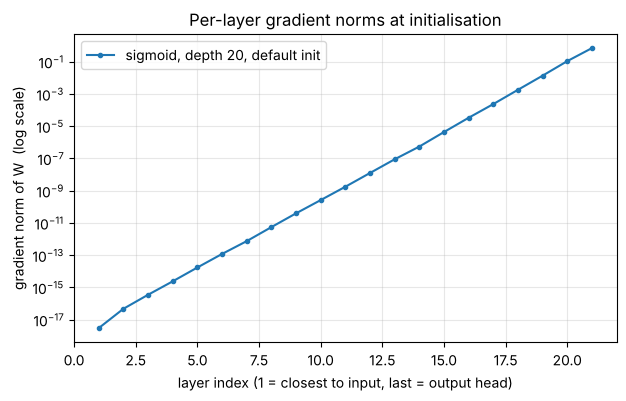

first hidden layer : 2.99e-18
last hidden layer  : 1.08e-01
ratio              : 2.78e-17


In [9]:
set_seed(0)
model = init_weights(DeepMLP(depth=20, act="sigmoid"), "default")
g_sig = grads_at_init(model)
plot_layer_grads({"sigmoid, depth 20, default init": g_sig}, "Per-layer gradient norms at initialisation")
print("first hidden layer : %.2e" % g_sig[0])
print("last hidden layer  : %.2e" % g_sig[-2])
print("ratio              : %.2e" % (g_sig[0] / g_sig[-2]))

The early layers receive gradients many orders of magnitude smaller than the later ones, so with SGD they barely move
(update = learning rate × gradient). Does this actually hurt training? Compare a **2-layer** and a **20-layer** sigmoid network
with identical optimiser settings:

depth  2 | final val acc 0.871 | final train loss 0.3280


depth 20 | final val acc 0.500 | final train loss 0.6941


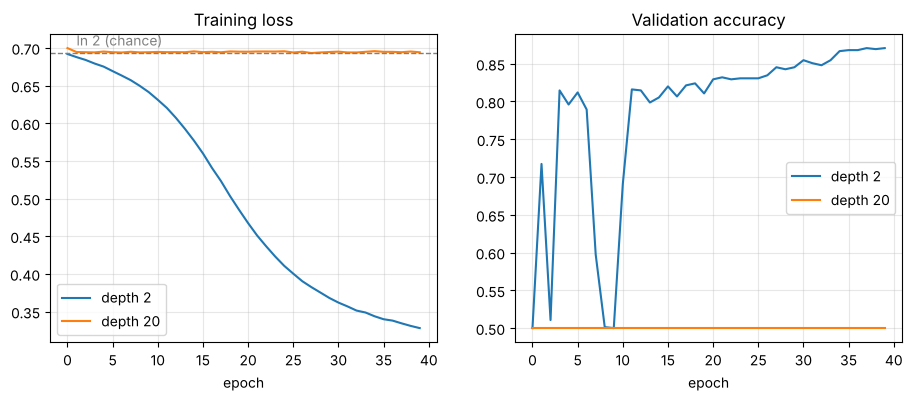

In [10]:
results = {}
for d in [2, 20]:
    set_seed(0)
    model = init_weights(DeepMLP(depth=d, act="sigmoid"), "default")
    results[d] = train(model, epochs=40, lr=0.05)
    print(f"depth {d:2d} | final val acc {results[d]['val_acc'][-1]:.3f} | final train loss {results[d]['train_loss'][-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for d, h in results.items():
    axes[0].plot(h["train_loss"], label=f"depth {d}")
    axes[1].plot(h["val_acc"], label=f"depth {d}")
axes[0].set_title("Training loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].set_title("Validation accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
axes[0].axhline(math.log(2), color="gray", ls="--", lw=1)
axes[0].text(1, math.log(2) + 0.01, "ln 2 (chance)", color="gray")
plt.show()

**What to notice:** the deep sigmoid network's loss stays near $\ln 2 \approx 0.693$, the loss of a model that predicts 50/50,
because the signal from the loss cannot travel back to the early layers. The shallow network, with the *same* activation and optimiser,
learns easily. The deep network has more capacity, so this is an **optimisation** failure, not a modelling one.

## 7. Experiment 2 — Exploding gradients

Now keep the activation friendly (ReLU, derivative = 1 for positive inputs) and attack the **weights** instead.
He initialisation uses $\text{std}=\sqrt{2/n_{in}}$, which keeps the variance of activations (and gradients) roughly constant across layers.
We multiply the weights by a `scale` to push each layer's gain below or above that sweet spot:

* `scale = 0.5` → gain per layer < 1 → **vanishing**
* `scale = 1.0` → variance-preserving → **stable**
* `scale = 1.5` → gain per layer > 1 → **exploding**

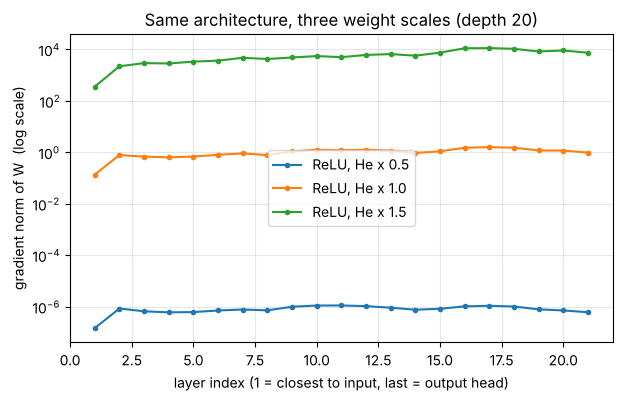

ReLU, He x 0.5   | first layer 1.47e-07 | last hidden 7.15e-07 | global norm 3.88e-06
ReLU, He x 1.0   | first layer 1.38e-01 | last hidden 1.17e+00 | global norm 4.94e+00
ReLU, He x 1.5   | first layer 3.58e+02 | last hidden 9.18e+03 | global norm 3.02e+04


In [11]:
EXPLODE = 1.5      # weight scale used for the "exploding" configuration from here on

curves = {}
for s in [0.5, 1.0, EXPLODE]:
    set_seed(0)
    model = init_weights(DeepMLP(depth=20, act="relu"), "he", scale=s)
    curves[f"ReLU, He x {s}"] = grads_at_init(model)

plot_layer_grads(curves, "Same architecture, three weight scales (depth 20)")
for k, v in curves.items():
    print(f"{k:<16} | first layer {v[0]:.2e} | last hidden {v[-2]:.2e} | global norm {np.sqrt((v**2).sum()):.2e}")

One scalar knob moves the same network from vanishing, through stable, to exploding.

> **Diagnostic note.** For *exploding* gradients, look at the **absolute magnitude** (or the global norm), not the first-vs-last-layer ratio.
> The huge activations inflate the gradient of *every* layer, so the ratio can look unremarkable even though the numbers are enormous.

Now train the exploding configuration with plain SGD and print what happens step by step:

In [12]:
set_seed(0)
model = init_weights(DeepMLP(depth=20, act="relu"), "he", scale=EXPLODE)
h_exp = train(model, epochs=40, lr=0.05)

total = np.sqrt((h_exp["grad_norms"] ** 2).sum(axis=1))      # global gradient norm per step
print(f"{'step':>4} | {'loss':>12} | {'global grad norm':>16}")
for i, (l, g) in enumerate(zip(h_exp["step_loss"], total)):
    print(f"{i:4d} | {l:12.4e} | {g:16.4e}")
print("diverged:", h_exp["diverged"])

step |         loss | global grad norm
   0 |   1.1904e+03 |       3.0655e+04
   1 |          nan |              inf
diverged: True


The very first batch already has a loss around $10^{3}$ and a gradient norm in the tens of thousands (a healthy network has a norm of order 1).
One SGD step later the weights are so extreme that the loss is `NaN`: the run is over after a single update. In real projects the same story reads: **"the loss suddenly became `NaN`"**.

**Gradient clipping** is the emergency brake: rescale the gradient so its global norm never exceeds a threshold
(`torch.nn.utils.clip_grad_norm_`). Below we train the *same* exploding network with `clip=1.0`; the recorded norms are the raw ones, *before* clipping.

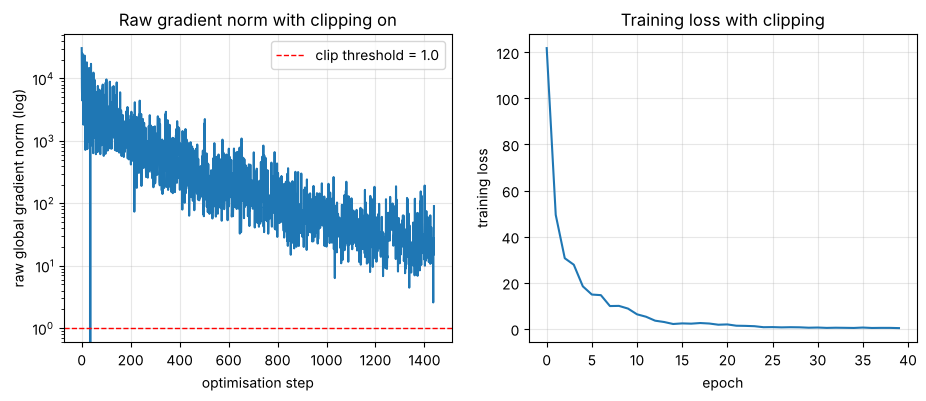

diverged: False | final val acc: 0.827
raw global grad norm: first step 3.07e+04 | median 1.23e+02 | last step 9.02e+01


In [13]:
set_seed(0)
model = init_weights(DeepMLP(depth=20, act="relu"), "he", scale=EXPLODE)
h_clip = train(model, epochs=40, lr=0.05, clip=1.0)
total_clip = np.sqrt((h_clip["grad_norms"] ** 2).sum(axis=1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(total_clip)
axes[0].axhline(1.0, color="red", ls="--", lw=1, label="clip threshold = 1.0")
axes[0].set_yscale("log")
axes[0].set_xlabel("optimisation step"); axes[0].set_ylabel("raw global gradient norm (log)")
axes[0].set_title("Raw gradient norm with clipping on"); axes[0].legend()
axes[1].plot(h_clip["train_loss"])
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("training loss"); axes[1].set_title("Training loss with clipping")
plt.show()

print(f"diverged: {h_clip['diverged']} | final val acc: {h_clip['val_acc'][-1]:.3f}")
print(f"raw global grad norm: first step {total_clip[0]:.2e} | median {np.median(total_clip):.2e} | last step {total_clip[-1]:.2e}")

The raw norm stays far above the threshold (median around $10^{2}$ versus $1.0$), so *every* step is clipped. Clipping keeps training alive, but note what it does **not** do: it treats the symptom (a giant step) rather than the cause (a badly scaled network),
so training is typically still slower or worse than with a properly scaled initialisation. We compare it with the cures in the next section.

## 8. Fixes — a side-by-side comparison

| Remedy | Idea | Mainly helps against |
|--------|------|----------------------|
| **ReLU-family activations** | derivative is 1 on the active side instead of ≤ 0.25 | vanishing |
| **Xavier / He initialisation** | choose weight scale so activation/gradient variance is preserved | both |
| **BatchNorm / LayerNorm** | re-normalise activations each layer, making training much less sensitive to weight scale | both |
| **Residual connections** | the skip path gives gradients an identity route ($\partial h_{l+1}/\partial h_l = I + \dots$) | vanishing |
| **Gradient clipping** | cap the global gradient norm before the update | exploding |

We train ten 20-layer configurations with identical data, optimiser and learning rate, and compare them.

In [14]:
DEPTH, EPOCHS, LR = 20, 40, 0.05

configs = {
    "sigmoid | default init (baseline)":      dict(act="sigmoid", init="default"),
    "sigmoid | Xavier":                       dict(act="sigmoid", init="xavier"),
    "tanh | Xavier":                          dict(act="tanh",    init="xavier"),
    "ReLU | He":                              dict(act="relu",    init="he"),
    "ReLU | He + BatchNorm":                  dict(act="relu",    init="he", norm="bn"),
    "sigmoid | default init + residual":      dict(act="sigmoid", init="default", residual=True),
    "ReLU | He + residual (no norm)":         dict(act="relu",    init="he", residual=True),
    f"ReLU | {EXPLODE}x He (exploding)":      dict(act="relu",    init="he", scale=EXPLODE),
    f"ReLU | {EXPLODE}x He + grad clipping":  dict(act="relu",    init="he", scale=EXPLODE, clip=1.0),
    f"ReLU | {EXPLODE}x He + BatchNorm":      dict(act="relu",    init="he", scale=EXPLODE, norm="bn"),
}

runs = {}
for name, cfg in configs.items():
    set_seed(0)
    model = DeepMLP(depth=DEPTH, act=cfg["act"], norm=cfg.get("norm"), residual=cfg.get("residual", False))
    init_weights(model, cfg["init"], cfg.get("scale", 1.0))
    g0 = grads_at_init(model)
    t0 = time.time()
    h = train(model, epochs=EPOCHS, lr=LR, clip=cfg.get("clip"))
    runs[name] = dict(hist=h, g0=g0, secs=time.time() - t0)
    acc = h["val_acc"][-1] if h["val_acc"] else float("nan")
    print(f"{name:<38} | val acc {acc:.3f} | diverged: {h['diverged']} | {runs[name]['secs']:.1f}s")

sigmoid | default init (baseline)      | val acc 0.500 | diverged: False | 7.7s


sigmoid | Xavier                       | val acc 0.500 | diverged: False | 7.9s


tanh | Xavier                          | val acc 0.965 | diverged: False | 7.3s


ReLU | He                              | val acc 0.957 | diverged: False | 7.7s


ReLU | He + BatchNorm                  | val acc 0.967 | diverged: False | 11.4s


sigmoid | default init + residual      | val acc 0.871 | diverged: False | 9.1s
ReLU | He + residual (no norm)         | val acc nan | diverged: True | 0.0s
ReLU | 1.5x He (exploding)             | val acc nan | diverged: True | 0.0s


ReLU | 1.5x He + grad clipping         | val acc 0.827 | diverged: False | 8.6s


ReLU | 1.5x He + BatchNorm             | val acc 0.963 | diverged: False | 13.6s


In [15]:
# summary table
print(f"{'configuration':<38} {'first/last-hidden':>18} {'global norm':>12} {'val acc':>8} {'status':>9}")
print(f"{'':<38} {'grad ratio @init':>18} {'@init':>12}")
print("-" * 92)
for name, r in runs.items():
    h, g0 = r["hist"], r["g0"]
    ratio = g0[0] / g0[-2]
    gnorm = np.sqrt((g0 ** 2).sum())
    acc = h["val_acc"][-1] if h["val_acc"] else float("nan")
    if h["diverged"]:   status = "DIVERGED"
    elif acc > 0.90:    status = "ok"
    elif acc > 0.60:    status = "slow"
    else:               status = "stuck"
    print(f"{name:<38} {ratio:>18.2e} {gnorm:>12.2e} {acc:>8.3f} {status:>9}")
print("\nRatio near 0 -> vanishing. Global norm >> 1 -> exploding. Healthy: ratio not tiny AND global norm of order 1.")

configuration                           first/last-hidden  global norm  val acc    status
                                         grad ratio @init        @init
--------------------------------------------------------------------------------------------
sigmoid | default init (baseline)                2.78e-17     6.98e-01    0.500     stuck
sigmoid | Xavier                                 4.26e-13     6.78e-01    0.500     stuck
tanh | Xavier                                    3.44e-01     1.37e+00    0.965        ok
ReLU | He                                        1.17e-01     4.94e+00    0.957        ok
ReLU | He + BatchNorm                            8.42e+00     1.18e+01    0.967        ok
sigmoid | default init + residual                2.11e-02     4.07e+01    0.871      slow
ReLU | He + residual (no norm)                   3.76e-02     8.58e+04      nan  DIVERGED
ReLU | 1.5x He (exploding)                       3.90e-02     3.02e+04      nan  DIVERGED
ReLU | 1.5x He + grad clip

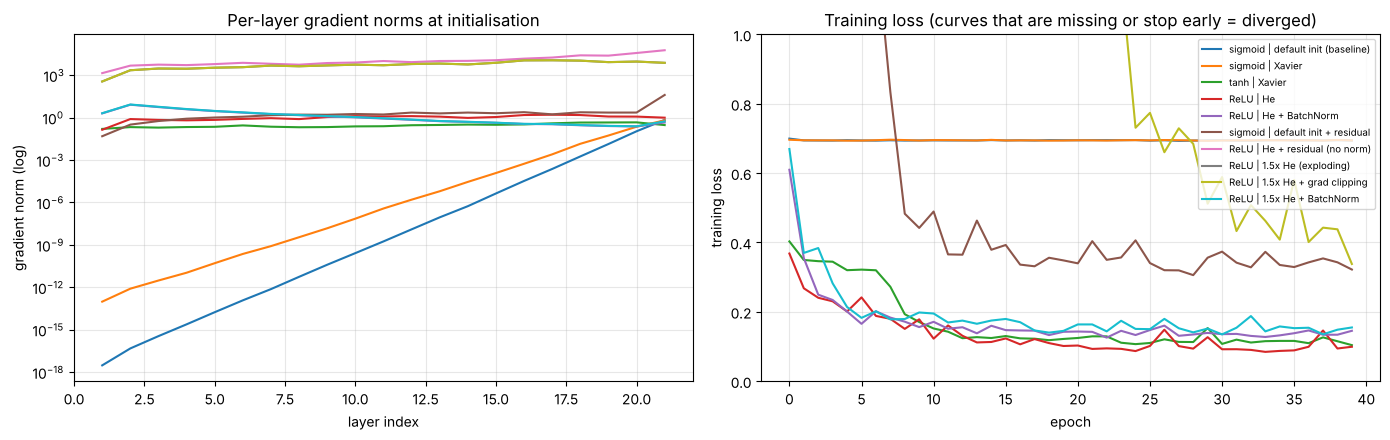

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# (a) per-layer gradient norms at initialisation
for name, r in runs.items():
    axes[0].plot(range(1, len(r["g0"]) + 1), r["g0"], label=name, lw=1.5)
axes[0].set_yscale("log")
axes[0].set_xlabel("layer index"); axes[0].set_ylabel("gradient norm (log)")
axes[0].set_title("Per-layer gradient norms at initialisation")

# (b) training loss curves
for name, r in runs.items():
    axes[1].plot(r["hist"]["train_loss"], label=name, lw=1.5)
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("training loss")
axes[1].set_title("Training loss (curves that are missing or stop early = diverged)")
axes[1].set_ylim(0, 1.0)
axes[1].legend(fontsize=7, loc="upper right")
plt.tight_layout()
plt.show()

### 8.1 What the comparison shows
Read the table above together with the plots (exact numbers vary slightly across machines and library versions, the pattern does not):

* **Baseline vs Xavier (sigmoid).** The deep sigmoid network is stuck at 50% accuracy with a first/last gradient ratio around $10^{-17}$.
  Xavier initialisation alone does **not** rescue it (still 50%, ratio around $10^{-13}$): it fixes the *weight* gain, but sigmoid's slope is at most 0.25, so every layer still shrinks the gradient.
* **tanh + Xavier, ReLU + He.** Both are healthy at depth 20: the ratio is not tiny, the global gradient norm is of order 1, and validation accuracy is about 0.96. Their activation slopes are about 1 where it matters and the init matches them.
* **BatchNorm.** It trains well and also rescues the badly scaled $1.5\times$ He network (accuracy about 0.96), because each layer re-normalises its input regardless of the weight scale.
* **Residual connections.** The *same* sigmoid baseline that was stuck at 50% now learns (about 0.87), and its gradient ratio rises by many orders of magnitude. The skip path gives gradients a short route to the early layers.
* **Residual without normalisation (ReLU) diverges.** Skips fix the gradient *path*, but adding $f(h)$ to $h$ in every block makes the activations (and gradients, global norm around $10^{4}$ at init) grow with depth. Practical residual networks pair skips with normalisation or scaled branches (see exercise 5).
* **Gradient clipping.** It turns a `NaN` run into one that trains, but only to about 0.83: much worse than simply fixing the scale (ReLU + He, 0.96). Clipping treats the symptom, not the cause.

### 8.2 Seeing gradients flow through training
A heatmap of $\log_{10}$ gradient norm (layers on the y-axis, optimisation steps on the x-axis) is a compact way to monitor gradient health.
A healthy network has roughly uniform colour from top to bottom; vanishing shows up as a dark band for early layers,
exploding as a very bright band. (The plain exploding run is over after a couple of steps, so we show the clipped run, with norms recorded *before* clipping.)

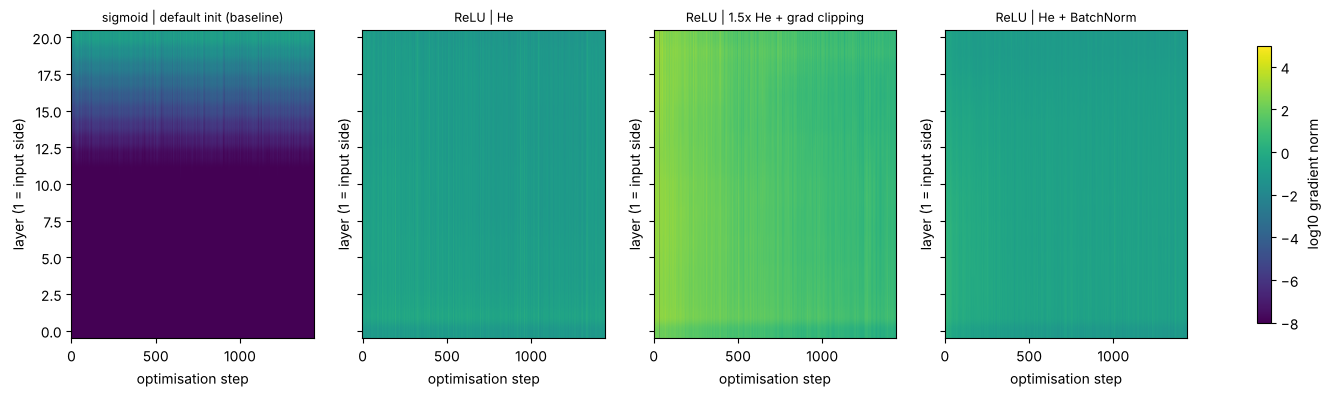

In [17]:
def grad_heatmap(ax, gn, title, vmin=-8, vmax=5):
    arr = np.log10(np.clip(gn, 1e-30, None)).T            # [layers, steps]
    im = ax.imshow(arr, aspect="auto", origin="lower", cmap="viridis", vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("optimisation step"); ax.set_ylabel("layer (1 = input side)")
    ax.grid(False)
    return im

names = ["sigmoid | default init (baseline)", "ReLU | He",
         f"ReLU | {EXPLODE}x He + grad clipping", "ReLU | He + BatchNorm"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, n in zip(axes, names):
    im = grad_heatmap(ax, runs[n]["hist"]["grad_norms"], n)
fig.colorbar(im, ax=axes, label="log10 gradient norm", shrink=0.9)
plt.show()

## 9. Takeaways

* Backprop multiplies one Jacobian per layer, so gradient magnitude changes **exponentially with depth**: factors below 1 vanish, factors above 1 explode.
* **Vanishing** is typical for deep sigmoid/tanh networks (derivatives ≤ 0.25 / ≤ 1) and for weights that are too small; early layers learn very slowly or not at all.
* **Exploding** is typical for weights that are too large (or recurrent networks that repeatedly apply the same matrix); symptoms are huge gradient norms and `NaN` loss.
* **Diagnose first:** log per-layer gradient norms (as in `layer_grad_norms`) and look at the ratio between early and late layers (vanishing) and at the absolute / global norm (exploding).
* **Remedies:** ReLU-family activations, Xavier/He initialisation, normalisation layers, residual connections, and gradient clipping. They address different parts of the product, and real architectures usually combine several. Clipping treats the symptom of exploding gradients; fixing the scale (init / normalisation) treats the cause.

## 10. Exercises

1. **Adam vs SGD.** Re-run the deep sigmoid baseline with `torch.optim.Adam`. Why does it make progress even though the raw gradients are tiny?
2. **Depth sweep.** Extend the depth sweep in 6.1 to include `tanh + Xavier` and `ReLU + He + BatchNorm`. Which ones stay flat as depth grows?
3. **Other activations.** Add `LeakyReLU` and `GELU` to the `acts` dictionary in `DeepMLP`. Do they behave like ReLU?
4. **Clipping threshold.** Sweep `clip` over `[0.1, 1, 10, 100]` for the exploding configuration (`EXPLODE = 1.5`). How does it trade off stability against speed?
5. **Residual details.** The plain ReLU residual network diverges while the sigmoid one trains. Try scaling the branch (`h = h + 0.2 * out`) or adding BatchNorm to the ReLU version. Why does that help?
6. **Recurrent networks.** Explain why the same product-of-Jacobians argument is even more severe for an RNN, where $W$ is *shared* across time steps. Then train a small `nn.RNN` and `nn.LSTM` on a long-range-dependency task and compare gradient norms.